# A01-GN — GMM trên RFM (RFM thô → StandardScaler → PCA giữ ≥ 90% phương sai)

Thí nghiệm **A01-GN** (người chạy: Thuận, hạn nội bộ 17/11/2026) theo chiến lược model. Mốc baseline của nhóm A. Quy trình: làm sạch → RFM → RFM thô → StandardScaler → PCA giữ ≥ 90% phương sai → GMM.


## Params

In [ ]:
FEATURES = ["Recency", "Frequency", "Monetary"]
RANDOM_STATE = 42
N_INIT = 10               
MAX_ITER = 300
TOL = 1e-3
REG_COVAR = 1e-6
INIT_PARAMS = "kmeans"
K_RANGE = range(2, 11)
COV_TYPES = ["full", "tied", "diag", "spherical"]
MIN_CLUSTER_FRAC = 0.01     

## Import thư viện và đọc dữ liệu

In [ ]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PowerTransformer, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)

def find(rel):
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())


DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figures"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

df = pd.read_csv(DATA, dtype={"CustomerID": "string"})
X = df[FEATURES].copy()
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 3)


,Recency,Frequency,Monetary
count,4327.00,4327.00,4327.00
mean,93.04,4.25,1944.95
std,99.98,7.64,8441.89
min,1.00,1.00,2.90
25%,18.00,1.00,301.52
50%,51.00,2.00,657.90
75%,143.00,5.00,1624.10
max,374.00,206.00,278748.02


**Nhận xét:** 4,327 khách, dùng chung file feature của nhóm. Monetary lệch phải rất mạnh (trung vị 657.9, max 278,748) nên tiền xử lý ảnh hưởng nhiều đến kết quả.

## Tiền xử lý

RFM thô → StandardScaler → PCA giữ ≥ 90% phương sai.

In [3]:
prep = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.9, svd_solver="full", random_state=RANDOM_STATE)),
])
Z = prep.fit_transform(X.values)
print("Kích thước đầu vào mô hình:", Z.shape)
ev = prep["pca"].explained_variance_ratio_
print("Phương sai từng PC:", ev.round(4), "| giữ lại:", round(ev.sum(), 4))

Kích thước đầu vào mô hình: (4327, 3)
Phương sai từng PC: [0.5638 0.3016 0.1345] | giữ lại: 1.0


## Quét k × covariance_type

Chỉ số chọn là **BIC** (thấp hơn tốt hơn). Silhouette/DBI/CHI tính trên đầu vào mô hình, chỉ để tham khảo.

Chọn: full, k=5, BIC=718.9, Silhouette=0.1349, cụm nhỏ nhất=49


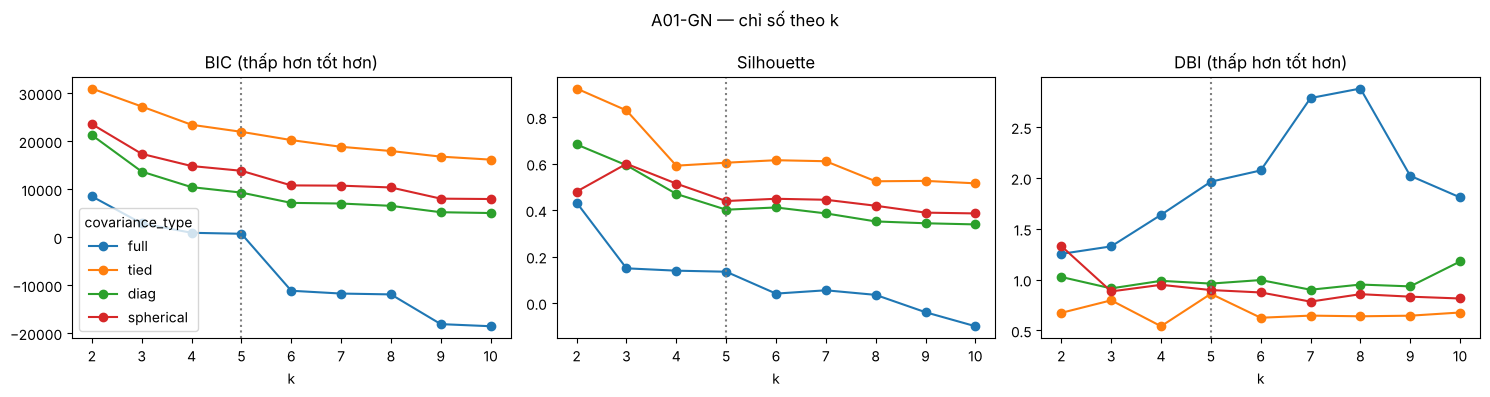

,covariance_type,k,BIC,AIC,Silhouette,DBI,CHI,min_cluster,converged
8,full,10,-18543.8805,-19174.7708,-0.0999,1.8090,896.4833,2,True
7,full,9,-18105.0794,-18672.2434,-0.0396,2.0213,902.9492,2,True
6,full,8,-11912.9358,-12416.3735,0.0351,2.8798,852.0910,3,True
5,full,7,-11736.0135,-12175.7249,0.0549,2.7861,1050.8372,3,True
4,full,6,-11151.4221,-11527.4072,0.0406,2.0741,591.9788,33,True
3,full,5,718.8844,406.6255,0.1349,1.9633,607.7270,49,True
2,full,4,924.1749,675.6424,0.1394,1.6374,826.0938,99,True
1,full,3,2879.5788,2694.7725,0.1495,1.3272,858.1067,217,True
26,diag,10,5041.3235,4601.6120,0.3386,1.1786,1825.9846,2,True
25,diag,9,5210.6039,4815.5008,0.3436,0.9337,1895.9330,3,True


In [4]:
def sweep(Xs):
    rows = []
    for cov in COV_TYPES:
        for k in K_RANGE:
            gm = GaussianMixture(n_components=k, covariance_type=cov, n_init=N_INIT, max_iter=MAX_ITER, tol=TOL,
                                 reg_covar=REG_COVAR, init_params=INIT_PARAMS, random_state=RANDOM_STATE).fit(Xs)
            lab = gm.predict(Xs); sizes = np.bincount(lab, minlength=k)
            ok = len(np.unique(lab)) > 1
            rows.append({"covariance_type": cov, "k": k, "BIC": gm.bic(Xs), "AIC": gm.aic(Xs),
                         "Silhouette": silhouette_score(Xs, lab) if ok else np.nan,
                         "DBI": davies_bouldin_score(Xs, lab) if ok else np.nan,
                         "CHI": calinski_harabasz_score(Xs, lab) if ok else np.nan,
                         "min_cluster": int(sizes.min()), "converged": bool(gm.converged_)})
    return pd.DataFrame(rows)

def select(res, n):
    ok = res[res["converged"] & (res["min_cluster"] >= MIN_CLUSTER_FRAC * n)]
    return ok.loc[ok["BIC"].idxmin()]

res = sweep(Z)
best = select(res, len(X))
print(f"Chọn: {best['covariance_type']}, k={int(best['k'])}, BIC={best['BIC']:,.1f}, "
      f"Silhouette={best['Silhouette']:.4f}, cụm nhỏ nhất={int(best['min_cluster'])}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["BIC", "Silhouette", "DBI"]):
    for cov in COV_TYPES:
        s = res[res["covariance_type"] == cov]
        ax.plot(s["k"], s[col], marker="o", label=cov)
    ax.axvline(int(best["k"]), color="gray", ls=":")
    ax.set_xlabel("k"); ax.set_title(col + (" (thấp hơn tốt hơn)" if col in ("BIC", "DBI") else ""))
axes[0].legend(title="covariance_type")
plt.suptitle("A01-GN — chỉ số theo k"); plt.tight_layout()
plt.savefig(FIG / "gmm_metrics.png", dpi=150); plt.show()
res.sort_values("BIC").head(10).round(4)

**Nhận xét:** BIC thấp nhất trong các cấu hình hội tụ và có cụm ≥ 1% khách là `full`, k=5 (BIC 718.9); cụm nhỏ nhất 49 khách. Silhouette 0.1349, DBI 1.9633. Có 5 cấu hình BIC thấp hơn nhưng bị loại do cụm quá nhỏ (< 1%) hoặc không hội tụ. Silhouette thấp: GMM là mô hình xác suất, các cụm chồng lấn nên chỉ số này chỉ để tham khảo.

## Train mô hình cuối

In [5]:
GM_ARGS = dict(n_components=int(best["k"]), covariance_type=best["covariance_type"], n_init=N_INIT, max_iter=MAX_ITER,
               tol=TOL, reg_covar=REG_COVAR, init_params=INIT_PARAMS, random_state=RANDOM_STATE)
model = Pipeline([("prep", Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=0.9, svd_solver="full", random_state=RANDOM_STATE)),
    ])),
                  ("gmm", GaussianMixture(**GM_ARGS))]).fit(X.values)
gm = model["gmm"]
assert np.allclose(model["prep"].transform(X.values), Z)
labels = gm.predict(Z)
proba = gm.predict_proba(Z)
print("Hội tụ:", gm.converged_, "| số vòng EM:", gm.n_iter_)
print("Số khách mỗi cụm:", dict(enumerate(np.bincount(labels).tolist())))
print("Silhouette:", round(silhouette_score(Z, labels), 4), "| DBI:", round(davies_bouldin_score(Z, labels), 4))

Hội tụ: True | số vòng EM: 13
Số khách mỗi cụm: {0: 2129, 1: 1536, 2: 503, 3: 110, 4: 49}
Silhouette: 0.1349 | DBI: 1.9633


## Hồ sơ cụm (trên RFM gốc, trung vị)

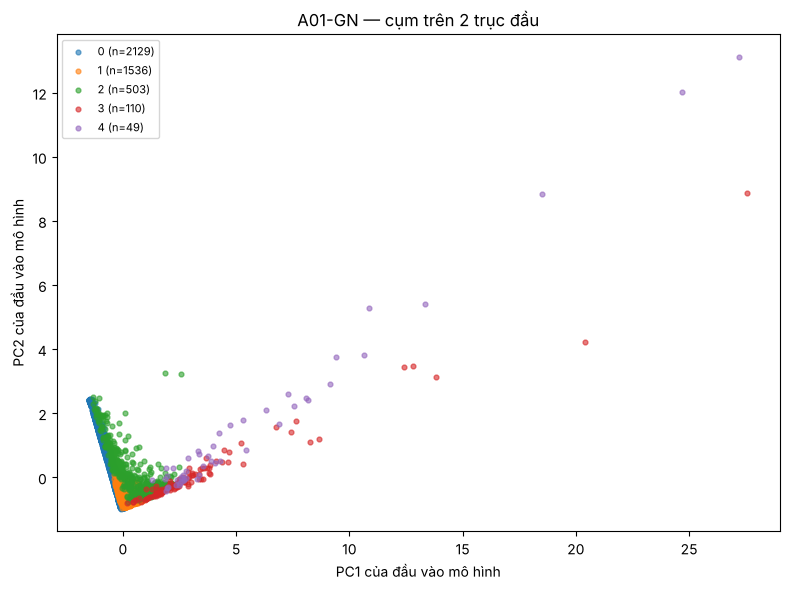

,customers,Recency,Frequency,Monetary,customer_share_pct,Monetary_share_pct
cluster,,,,,,
0,2129,117.0,1.0,304.6,49.2,8.6
1,1536,26.0,4.0,1290.6,35.5,27.2
2,503,58.0,6.0,3596.3,11.6,23.2
3,110,3.0,21.0,7958.6,2.5,15.8
4,49,11.0,25.0,19766.6,1.1,25.2


In [6]:
prof = X.assign(cluster=labels).groupby("cluster").agg(
    customers=("Monetary", "size"), Recency=("Recency", "median"), Frequency=("Frequency", "median"),
    Monetary=("Monetary", "median"), Monetary_sum=("Monetary", "sum"))
prof["customer_share_pct"] = (100 * prof["customers"] / len(X)).round(2)
prof["Monetary_share_pct"] = (100 * prof["Monetary_sum"] / prof["Monetary_sum"].sum()).round(2)
prof = prof.drop(columns="Monetary_sum").round(1)

coords = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Z) if Z.shape[1] > 2 else Z
fig, ax = plt.subplots(figsize=(8, 6))
for c in sorted(np.unique(labels)):
    m = labels == c
    ax.scatter(coords[m, 0], coords[m, 1], s=12, alpha=0.6, marker="x" if c == -1 else "o", label=f"{c} (n={m.sum()})")
ax.set_xlabel("PC1 của đầu vào mô hình"); ax.set_ylabel("PC2 của đầu vào mô hình"); ax.legend(fontsize=8)
ax.set_title("A01-GN — cụm trên 2 trục đầu")
plt.tight_layout(); plt.savefig(FIG / "gmm_clusters_pca.png", dpi=150); plt.show()
prof

**Nhận xét:** Cụm 4 có Monetary trung vị cao nhất (19,767), gồm 49 khách (1.1%) nhưng chiếm 25.2% tổng Monetary. Cụm 0 đông nhất (49.2% khách, Recency trung vị 117 ngày).

## Lưu kết quả

In [8]:
res.to_csv(OUT / "gmm_a01_grid.csv", index=False)
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels, "max_proba": proba.max(axis=1).round(4)}) \
    .to_csv(OUT / "gmm_a01_labels.csv", index=False)
joblib.dump(model, "gmm_a01_model.pkl")
params = {"experiment": "A01-GN", "features": FEATURES, "transform": None,
          "scaler": "StandardScaler", "pca": 0.9,
          "n_components": int(Z.shape[1]), "n_customers": int(len(X)),
          "pca_variance_kept": float(model["prep"]["pca"].explained_variance_ratio_.sum()),
          "covariance_type": best["covariance_type"], "k": int(best["k"]), "bic": float(best["BIC"]), "aic": float(best["AIC"]),
          "silhouette": float(best["Silhouette"]), "dbi": float(best["DBI"]), "chi": float(best["CHI"]),
          "min_cluster": int(best["min_cluster"]), "converged": bool(gm.converged_), "n_iter": int(gm.n_iter_),
          "gmm_params": {k: v for k, v in gm.get_params().items()}}
json.dump(params, open(OUT / "gmm_a01_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2, default=str)
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['gmm_a01_grid.csv', 'gmm_a01_labels.csv', 'gmm_a01_params.json']


**Kết luận A01-GN:** GMM `full` k=5 (BIC 718.9) trên 3 chiều đầu vào. Silhouette giữa các cấu hình khác không gian đầu vào (số chiều, scaler) không so sánh trực tiếp được; dùng ARI và hồ sơ cụm trên RFM gốc để so sánh.